# The leverage gap: users per employee

How many people does each employee serve? This notebook rebuilds the chart from public evidence, number by number, with the [Croma API](https://usecroma.com):

- **Croma Web Search** (`/global/web-search/v1`) finds the filing, press release or article behind each figure.
- **Croma Research** (`/global/research/v1`) answers the same question independently, with citations, as a second opinion.

**The question.** For 13 consumer and fintech companies: the latest reported number of users, the latest reported headcount, and the ratio between them.

**The rule.** No number goes on the chart without a source URL and a verbatim quote, and the notebook checks that every quote is really in the evidence the API returned. The choice of which figure to use is a judgment call, so it lives in a plain CSV (`data/figures.csv`) that anyone can read, dispute and edit.

**How to run it.** Every API response is saved under `data/` the first time it is requested, and read from there afterwards. Without `CROMA_API_KEY` the notebook runs entirely on that snapshot (retrieved 13 November 2026). With an API Key it only queries what is missing: delete a file in `data/search/` or `data/research/` to refresh it.

In [1]:
import json
import re
import sys
from pathlib import Path

import pandas as pd
import requests

sys.path.insert(0, str(Path.cwd().parent))
import croma

DATA = Path("data")
CHARTS = Path("charts")
for folder in (DATA / "search", DATA / "research", CHARTS):
    folder.mkdir(parents=True, exist_ok=True)
ONLINE = croma.has_key()
print("Querying the Croma API for anything not saved yet" if ONLINE else "No CROMA_API_KEY: reading the snapshot in data/")

pd.set_option("display.max_colwidth", 90)

Querying the Croma API for anything not saved yet


## The companies

Each company has one audience metric, the one it reports itself. They are not the same metric: Reddit reports weekly uniques, Meta reports daily people across its family of apps, the fintechs report customers. The chart says which is which.

Each company also has its search queries. The first query per figure is the generic one. The second, where there is one, is a follow-up written after reading the first results, when they did not settle the number.

In [2]:
COMPANIES = pd.DataFrame(
    [
        ("telegram", "Telegram", "consumer", "monthly active users", "users"),
        ("snap", "Snap", "consumer", "monthly active users", "users"),
        ("reddit", "Reddit", "consumer", "weekly active uniques", "weekly"),
        ("midjourney", "Midjourney", "consumer", "registered users", "registered"),
        ("duolingo", "Duolingo", "consumer", "monthly active users", "users"),
        ("pinterest", "Pinterest", "consumer", "monthly active users", "users"),
        ("spotify", "Spotify", "consumer", "monthly active users", "users"),
        ("lovable", "Lovable", "consumer", "users", "users"),
        ("meta", "Meta", "consumer", "family daily active people", "daily"),
        ("canva", "Canva", "consumer", "monthly active users", "users"),
        ("nubank", "Nubank", "fintech", "customers", "customers"),
        ("revolut", "Revolut", "fintech", "customers", "customers"),
        ("wise", "Wise", "fintech", "active customers", "customers"),
    ],
    columns=["slug", "name", "group", "metric", "noun"],
).set_index("slug")

QUERIES = {
    "telegram": {
        "users": ["Telegram monthly active users 2026 billion Durov"],
        "staff": ["Telegram number of employees team size Durov engineers",
                  "Telegram total employees headcount Financial Times bond prospectus staff"],
    },
    "snap": {
        "users": ["Snap Q3 2026 results monthly active users"],
        "staff": ["Snap Inc full-time employees headcount 2026"],
    },
    "reddit": {
        "users": ["Reddit Q3 2026 results weekly active uniques"],
        "staff": ["Reddit full-time employees headcount 2026"],
    },
    "midjourney": {
        "users": ["Midjourney registered users Discord members 2026"],
        "staff": ["Midjourney number of employees 2026", "Midjourney team size full-time staff David Holz Sacra"],
    },
    "duolingo": {
        "users": ["Duolingo Q3 2026 monthly active users shareholder letter"],
        "staff": ["Duolingo full-time employees headcount 2026"],
    },
    "pinterest": {
        "users": ["Pinterest Q3 2026 results global monthly active users"],
        "staff": ["Pinterest full-time employees headcount 2026"],
    },
    "spotify": {
        "users": ["Spotify Q3 2026 results monthly active users"],
        "staff": ["Spotify full-time employees Q3 2026"],
    },
    "lovable": {
        "users": ["Lovable AI app builder number of users 2026", "Lovable Series C August 2026 users employees Anton Osika"],
        "staff": ["Lovable AI app builder number of employees 2026"],
    },
    "meta": {
        "users": ["Meta Q3 2026 results family daily active people"],
        "staff": ["Meta Q3 2026 results headcount"],
    },
    "canva": {
        "users": ["Canva monthly active users 2026"],
        "staff": ["Canva number of employees 2026", "Canva total employees headcount before November 2026 layoffs"],
    },
    "nubank": {
        "users": ["Nu Holdings Q3 2026 results customers"],
        "staff": ["Nubank Nu Holdings number of employees 2026"],
    },
    "revolut": {
        "users": ["Revolut customers 2026 million"],
        "staff": ["Revolut employees headcount 2026", "Revolut annual report 2025 number of employees headcount"],
    },
    "wise": {
        "users": ["Wise plc FY2026 results active customers"],
        "staff": ["Wise plc FY2026 annual report employees"],
    },
}
COMPANIES

,name,group,metric,noun
slug,,,,
telegram,Telegram,consumer,monthly active users,users
snap,Snap,consumer,monthly active users,users
reddit,Reddit,consumer,weekly active uniques,weekly
midjourney,Midjourney,consumer,registered users,registered
duolingo,Duolingo,consumer,monthly active users,users
pinterest,Pinterest,consumer,monthly active users,users
spotify,Spotify,consumer,monthly active users,users
lovable,Lovable,consumer,users,users
meta,Meta,consumer,family daily active people,daily


## 1. Evidence: Croma Web Search

One call per query, eight results each. A result carries the URL, the title, the publication date and `highlights`: the passages of the page that answer the query. Those passages are the evidence everything else is checked against.

In [3]:
def cached(path: Path, fetch):
    if not path.exists():
        if not ONLINE:
            return None
        try:
            path.write_text(json.dumps(fetch(), ensure_ascii=False, indent=1))
        except requests.HTTPError as error:
            if error.response.status_code != 429:
                raise
            print(f"Rate limited, run again after the hourly reset: {path.name}")
            return None
    return json.loads(path.read_text())


def search(slug: str, kind: str, n: int, query: str) -> list[dict]:
    data = cached(DATA / "search" / f"{slug}-{kind}-{n}.json",
                  lambda: croma.call("/global/web-search/v1", query=query, limit=8))
    return [{"company": slug, "figure": kind, "query": query, **result} for result in (data or {}).get("results", [])]


evidence = pd.DataFrame([
    row
    for slug, kinds in QUERIES.items()
    for kind, queries in kinds.items()
    for n, query in enumerate(queries, start=1)
    for row in search(slug, kind, n, query)
])
evidence["text"] = evidence.title.fillna("") + " " + evidence.highlights.map(lambda parts: " ".join(parts or []))
print(f"{evidence['query'].nunique()} searches, {len(evidence)} results, {evidence.url.nunique()} distinct pages")
evidence.pivot_table(index="company", columns="figure", values="url", aggfunc="count").reindex(COMPANIES.index)

31 searches, 248 results, 232 distinct pages


figure,staff,users
slug,,
telegram,16,8
snap,8,8
reddit,8,8
midjourney,16,8
duolingo,8,8
pinterest,8,8
spotify,8,8
lovable,8,16
meta,8,8


What a result looks like. Meta's press release answers both questions in one page:

In [4]:
sample = evidence[(evidence.company == "meta") & (evidence.figure == "staff")].iloc[0]
print(sample.url)
print(sample.published_at)
print()
print(sample.text[:900])

https://investor.atmeta.com/investor-news/press-release-details/2026/Meta-Reports-Third-Quarter-2026-Results/default.aspx
2026-10-21T00:00:00.000Z

Meta - Meta Reports Third Quarter 2026 Results MENLO PARK, Calif., Oct. 21, 2026 /PRNewswire/ -- Meta Platforms, Inc. (Nasdaq: META) today reported financial results for the quarter ended September 30, 2026.

...

Three Months Ended September 30,

 % Change

In millions, except percentages and per share amounts

2026

2025

Revenue

$ 64,601

$ 51,242

26 %

Costs and expenses

51,613

30,707

68 %

Income from operations

$ 12,988

$ 20,535

(37) %

Operating margin

20 %

40 %

Provision for income taxes

$ 3,141

$ 18,954

(83) %

Effective tax rate

24 %

87 %

Net income

$ 9,860

$ 2,709

264 %

Diluted earnings per share (EPS)

$ 3.83

$ 1.05

265 %

...

Third Quarter 2026 Operational and Other Financial Highlights

- Family daily active people (DAP) – DAP was 3.64 billion on average for September 2026, an increase of 3% year-over-y

## 2. A second opinion: Croma Research

The same question, asked in plain language, once per company. Research reads live sources and writes a short report with numbered citations. It is used here as a cross-check, never as the source of a number: where the report and the search evidence disagree, the disagreement is the interesting part.

In [5]:
def research(slug: str) -> dict | None:
    company = COMPANIES.loc[slug]
    question = (f"What is {company['name']}'s most recently reported number of {company.metric}, and its most recently "
                f"reported number of full-time employees? Give each figure with its reporting period and the primary source.")
    return cached(DATA / "research" / f"{slug}.json", lambda: croma.call("/global/research/v1", query=question))


reports = {slug: report for slug in COMPANIES.index if (report := research(slug))}
for slug, report in reports.items():
    print(f"== {COMPANIES.loc[slug, 'name']} ({report['pages_analyzed']} pages)")
    print(report["report"])
    print()

== Telegram (8 pages)
Telegram’s most recently reported monthly active users are “significantly more than 1 billion” monthly active users, reported by Pavel Durov on March 19, 2025 [1]. Telegram’s most recently reported full-time employee count in the provided sources is about 30 full-time employees, reported in March 2025 as “about 30 full-time employees” [2]. The primary sources are TASS (for the MAU figure) [1] and Contrary Research (for the employee figure) [2].

== Snap (8 pages)
Snap most recently reported 977 million monthly active users (MAUs) for the quarter ended September 30, 2026, in its Q3 2026 financial results press release / accompanying materials [1][2]. Snap most recently reported 4,540 full-time employees for the quarter ended September 30, 2026 (full-time; excluding part-time, contractors, and temporary personnel), in the same Q3 2026 supplemental financial information table [1].

== Reddit (8 pages)
Reddit’s most recently reported Weekly Active Uniques (WAUq) is 51

## 3. The figures

`data/figures.csv` is the one hand-made file: for each company, the figure chosen from the evidence, where it comes from and the sentence that states it. The choices follow three rules:

1. **Users**: the latest figure the company itself has reported.
2. **Employees**: the latest headcount the company has reported, in a filing, an annual report or its own words. Public companies make this easy. Private ones do not, so every other credible figure found is kept too, marked `alt`, and section 6 shows how much the answer moves with it.
3. **Never a LinkedIn count.** Profile counts include contractors, alumni and people who list the company by mistake. Canva has about 5,500 employees and more than 20,000 LinkedIn profiles.

`basis` says who is speaking: the company (`company-reported`), a newspaper citing it (`press report`) or a data provider (`third-party estimate`).

In [6]:
figures = pd.read_csv(DATA / "figures.csv")
figures[["company", "metric", "value", "as_of", "basis", "use", "quote"]]

,company,metric,value,as_of,basis,use,quote
0,telegram,users,1000000000,2025-03,company-reported,chart,Telegram now has significantly over 1 billion monthly active users
1,telegram,staff,100,2026-01,press report,chart,Telegram has fewer than 100 full-time staff
2,telegram,staff,60,2023,company-reported,alt,an agile core team of around 60
3,telegram,staff,30,2024-04,company-reported,alt,Only 30 Staff
4,snap,users,977000000,2026-09,company-reported,chart,Monthly Active Users grew to 977 million
5,snap,staff,4540,2026-09,company-reported,chart,"Snap counted 4,540 full-time employees at quarter-end"
6,reddit,users,515200000,2026-09,company-reported,chart,increased 16% year-over-year to 515.2 million
7,reddit,staff,2555,2025-12,company-reported,chart,"As of December 31, 2025, we had 2,555 employees"
8,midjourney,users,19830000,2026-01,third-party estimate,chart,19.83 million registered users on its Discord server
9,midjourney,staff,60,2026-11,company-reported,chart,community-funded research lab of 60 people


**The check.** Every quote must appear, word for word, in what the API returned for the page it is attributed to. Whitespace, case and curly quotes aside, nothing is fuzzy here: one missing quote stops the notebook.

In [7]:
def norm(text: str) -> str:
    text = str(text).replace("’", "'").replace("“", '"').replace("”", '"')
    return re.sub(r"\s+", " ", text).strip().lower()


pages = evidence.assign(text=evidence.text.map(norm)).groupby("url").text.apply(" ".join)
figures["verified"] = [norm(row.quote) in pages.get(row.url, "") for row in figures.itertuples()]
assert figures.verified.all(), figures[~figures.verified]
print(f"{figures.verified.sum()} of {len(figures)} quotes found verbatim in the evidence")

31 of 31 quotes found verbatim in the evidence


**The second opinion.** Does the Research report for each company state the same number? `False` is not an error. It marks the figures where a careful reader should look twice, and they are exactly the hard ones: private companies with no filing.

In [8]:
def spellings(value: int) -> list[str]:
    forms = [f"{value:,}"]
    for size, word in ((1e9, "billion"), (1e6, "million")):
        if value >= size:
            forms += [f"{value / size:.{d}f} {word}" for d in (0, 1, 2) if round(value / size, d) == value / size]
            break
    return forms


def research_says(row) -> bool | None:
    report = reports.get(row.company)
    return None if report is None else any(form in report["report"] for form in spellings(row.value))


chart_figures = figures[figures.use == "chart"].copy()
chart_figures["research_agrees"] = chart_figures.apply(research_says, axis=1)
agreement = chart_figures.pivot(index="company", columns="metric", values="research_agrees").reindex(COMPANIES.index)
agreement

metric,staff,users
slug,,
telegram,False,True
snap,True,True
reddit,False,True
midjourney,False,False
duolingo,True,True
pinterest,False,True
spotify,True,True
lovable,False,True
meta,True,True


## 4. Users per employee

In [9]:
def pick(metric: str) -> pd.DataFrame:
    return chart_figures[chart_figures.metric == metric].set_index("company")[["value", "approx", "as_of"]]


table = COMPANIES.join(pick("users").add_prefix("users_")).join(pick("staff").add_prefix("staff_"))
table = table.rename(columns={"users_value": "users", "staff_value": "staff"})
table["per_employee"] = table.users / table.staff
table = table.sort_values(["group", "per_employee"], ascending=[True, False])
table[["name", "group", "metric", "users", "users_as_of", "staff", "staff_as_of", "per_employee"]].round(0)

,name,group,metric,users,users_as_of,staff,staff_as_of,per_employee
slug,,,,,,,,
telegram,Telegram,consumer,monthly active users,1000000000,2025-03,100,2026-01,10000000.0
midjourney,Midjourney,consumer,registered users,19830000,2026-01,60,2026-11,330500.0
snap,Snap,consumer,monthly active users,977000000,2026-09,4540,2026-09,215198.0
reddit,Reddit,consumer,weekly active uniques,515200000,2026-09,2555,2025-12,201644.0
duolingo,Duolingo,consumer,monthly active users,153100000,2026-09,900,2025-12,170111.0
pinterest,Pinterest,consumer,monthly active users,661000000,2026-09,5192,2026-09,127311.0
spotify,Spotify,consumer,monthly active users,788000000,2026-09,7284,2026-09,108182.0
meta,Meta,consumer,family daily active people,3640000000,2026-09,66775,2026-09,54511.0
canva,Canva,consumer,monthly active users,265000000,2025-12,5500,2026-01,48182.0


In [10]:
def round_sig(value: float, digits: int = 2) -> int:
    return int(float(f"{value:.{digits}g}"))


top, bottom = table.per_employee.idxmax(), table.per_employee.idxmin()
gap = table.per_employee[top] / table.per_employee[bottom]
fintech = table[table.group == "fintech"].per_employee
best_fintech = fintech.idxmax()
multiples = (fintech[best_fintech] / fintech.drop(best_fintech)).rename(lambda slug: COMPANIES.loc[slug, "name"])

print(f"{COMPANIES.loc[top, 'name']}: {table.per_employee[top]:,.0f} users per employee")
print(f"{COMPANIES.loc[bottom, 'name']}: {table.per_employee[bottom]:,.0f} users per employee")
print(f"The gap: {gap:,.0f}x, about {round_sig(gap):,}x")
print(f"{COMPANIES.loc[best_fintech, 'name']} against the other fintechs: " + ", ".join(f"{m:.1f}x {name}" for name, m in multiples.items()))

Telegram: 10,000,000 users per employee
Wise: 2,148 users per employee
The gap: 4,656x, about 4,700x
Nubank against the other fintechs: 2.2x Revolut, 6.6x Wise


## 5. What changed against the first draft

The chart started as a draft compiled by hand. These are its numbers next to the ones the evidence supports. Most survive. Five do not, and each change has a reason in `data/figures.csv`.

In [11]:
DRAFT = pd.DataFrame(
    [
        ("telegram", 1_000_000_000, 100), ("snap", 977_000_000, 4_540), ("reddit", 515_000_000, 2_555),
        ("midjourney", 19_800_000, 107), ("duolingo", 153_000_000, 900), ("pinterest", 661_000_000, 5_265),
        ("spotify", 788_000_000, 7_284), ("lovable", 8_000_000, 146), ("meta", 3_640_000_000, 66_775),
        ("canva", 265_000_000, 5_500), ("nubank", 139_000_000, 10_000), ("revolut", 75_000_000, 19_500),
        ("wise", 18_900_000, 8_800),
    ],
    columns=["slug", "users", "staff"],
).set_index("slug")
DRAFT["per_employee"] = DRAFT.users / DRAFT.staff

compare = pd.DataFrame({
    "users, draft": DRAFT.users, "users, sourced": table.users,
    "staff, draft": DRAFT.staff, "staff, sourced": table.staff,
    "per employee, draft": DRAFT.per_employee.round(0), "per employee, sourced": table.per_employee.round(0),
}).reindex(table.index)
compare["change %"] = ((table.per_employee / DRAFT.per_employee - 1) * 100).round(0)
compare

,"users, draft","users, sourced","staff, draft","staff, sourced","per employee, draft","per employee, sourced",change %
slug,,,,,,,
telegram,1000000000,1000000000,100,100,10000000.0,10000000.0,0.0
midjourney,19800000,19830000,107,60,185047.0,330500.0,79.0
snap,977000000,977000000,4540,4540,215198.0,215198.0,0.0
reddit,515000000,515200000,2555,2555,201566.0,201644.0,0.0
duolingo,153000000,153100000,900,900,170000.0,170111.0,0.0
pinterest,661000000,661000000,5265,5192,125546.0,127311.0,1.0
spotify,788000000,788000000,7284,7284,108182.0,108182.0,0.0
meta,3640000000,3640000000,66775,66775,54511.0,54511.0,0.0
canva,265000000,265000000,5500,5500,48182.0,48182.0,0.0


In [12]:
moved = ((table[["users", "staff"]] / DRAFT[["users", "staff"]] - 1).abs() > 0.01).any(axis=1)
changed = [slug for slug in compare.index if moved[slug]]
for slug in changed:
    print(f"== {COMPANIES.loc[slug, 'name']}: {compare.loc[slug, 'change %']:+.0f}%")
    for row in figures[(figures.company == slug) & (figures.use == "chart")].itertuples():
        print(f"   {row.metric}: {row.value:,} ({row.as_of}, {row.basis})")
        print(f"   \"{row.quote}\"")
        print(f"   {row.url}")

== Midjourney: +79%
   users: 19,830,000 (2026-01, third-party estimate)
   "19.83 million registered users on its Discord server"
   https://www.demandsage.com/midjourney-statistics/
   staff: 60 (2026-11, company-reported)
   "community-funded research lab of 60 people"
   https://midjourney.com/
== Pinterest: +1%
   users: 661,000,000 (2026-09, company-reported)
   "increased 10% year over year to 661 million"
   https://www.sec.gov/Archives/edgar/data/1506293/000150629326000151/q3-26xpressrelease.htm
   staff: 5,192 (2026-09, company-reported)
   "Headcount was 5,192"
   https://pubt.io/view/DC04207BE7CD2F6B62604560F843FA3E56B47892
== Lovable: -51%
   users: 8,000,000 (2026-02, company-reported)
   "attract some 8 million users"
   https://techcrunch.com/2026/03/11/lovable-says-it-added-100m-in-revenue-last-month-alone-with-just-146-employees/
   staff: 300 (2026-08, company-reported)
   "We are still only around 300 people"
   https://www.linkedin.com/posts/ludvig-widmark-44424623

What the evidence says about each change:

- **Revolut** moves the most. Its 2025 annual report gives 12,200 employees at year end, not the roughly 19,500 to 21,000 that workforce trackers show, and its customer count has since passed 80 million. Nubank is still the most efficient of the three, by about 2x over Revolut rather than 4x.
- **Lovable** grew into its own statistic. The 146 employees are from February 2026. By its Series C in August the team was around 300, in the words of one of its own people that day, and the company said it would reach 450 by year end. The last user count it has published is still 8 million.
- **Midjourney** describes itself on its own site as a lab of 60 people. Third-party estimates run up to 165.
- **Nubank** reported third-quarter results on 12 November 2026: 143 million customers.
- **Pinterest** reported 5,192 employees at 30 September 2026, after its restructuring.

## 6. How much the answer depends on the headcount

For the companies with more than one credible headcount, the ratio under each. The chart uses the row marked `chart`.

In [13]:
staff_options = figures[figures.metric == "staff"].merge(table[["name", "users"]], left_on="company", right_index=True)
staff_options = staff_options[staff_options.groupby("company").value.transform("count") > 1]
staff_options["per_employee"] = (staff_options.users / staff_options.value).round(0)
staff_options.sort_values(["name", "value"])[["name", "value", "as_of", "basis", "use", "per_employee", "quote"]].set_index("name")

,value,as_of,basis,use,per_employee,quote
name,,,,,,
Lovable,146,2026-02,company-reported,alt,54795.0,with just 146 employees
Lovable,300,2026-08,company-reported,chart,26667.0,We are still only around 300 people
Midjourney,60,2026-11,company-reported,chart,330500.0,community-funded research lab of 60 people
Midjourney,165,2026-06,third-party estimate,alt,120182.0,approximately 165 total employees worldwide as of June 2026
Revolut,12200,2025-12,company-reported,chart,6557.0,"discloses 12,200 year-end employees"
Revolut,21207,2026-06,third-party estimate,alt,3772.0,"approximately 21,207 total employees worldwide as of June 2026"
Telegram,30,2024-04,company-reported,alt,33333333.0,Only 30 Staff
Telegram,60,2023,company-reported,alt,16666667.0,an agile core team of around 60
Telegram,100,2026-01,press report,chart,10000000.0,Telegram has fewer than 100 full-time staff


Telegram is the case to keep in mind. The chart uses the most conservative figure available, the Financial Times' "fewer than 100 full-time staff". With the "core team of around 60" Telegram itself has described, each employee serves about 17 million people. With Pavel Durov's 30 engineers, 33 million.

## Limits

- **The audiences are not the same thing.** Monthly users, weekly uniques, daily people, registered accounts and customers are different measures. The ratio compares orders of magnitude, which is why the chart is on a log scale. It does not rank Snap against Reddit.
- **Midjourney's audience is the weakest number here**: registered Discord accounts, counted by third-party trackers, not active users.
- **Headcount is employees.** Contractors and outsourced moderation are not in it, and for Telegram and Meta that is a large share of the people doing the work.
- **Dates differ.** Most figures are from September 2026, some headcounts from December 2025, Telegram's audience from March 2025. Each row carries its own date.
- **Canva** announced on 3 November 2026 that 1,271 people, 22% of the company, would be affected by a restructuring. The chart uses the headcount before it.
- A search returns what is on the web today. The snapshot in `data/` is what was there on 13 November 2026.

## Chart

The design is a 1200 by 1500 canvas, drawn here in pixel coordinates so every measure can be read straight from the code. Inter and Newsreader are in `fonts/`, so the output is the same on any machine.

In [14]:
import math

import matplotlib

matplotlib.use("Agg")
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
from matplotlib.patches import FancyBboxPatch, PathPatch
from matplotlib.path import Path as MplPath

W, H, DPI = 1200, 1500, 100
LEFT, RIGHT = 88, 1112
BAR_LEFT, BAR_RIGHT = 322, 992
ROW, ROW_GAP, BAR_HEIGHT = 48, 4, 24
PAPER, INK, ACCENT = "#F3EAE3", "#1A1714", "#D8232A"
SUBTITLE, SOFT, MUTED, RULE, DASH = "#3D3731", "#4A433C", "#5E564E", "#CDBFB3", "#BFAFA1"
BAR, BAR_QUIET = "#2E2A26", "#6E655C"
FONTS = {400: "Inter-Regular", 600: "Inter-SemiBold", 700: "Inter-Bold", 800: "Inter-ExtraBold", "serif": "Newsreader-Regular"}
ASCENT, LINE = 0.969, 1.21


class Canvas:
    def __init__(self):
        self.fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor=PAPER)
        self.ax = self.fig.add_axes([0, 0, 1, 1])
        self.ax.set(xlim=(0, W), ylim=(H, 0))
        self.ax.axis("off")
        self.renderer = self.fig.canvas.get_renderer()

    def font(self, weight, size) -> FontProperties:
        return FontProperties(fname=str(Path("fonts") / f"{FONTS[weight]}.ttf"), size=size * 72 / DPI)

    def width(self, s, size, weight=400, tracking=0.0) -> float:
        return self.renderer.get_text_width_height_descent(s, self.font(weight, size), False)[0] + tracking * size * (len(s) - 1)

    def text(self, x, top, s, size, weight=400, color=INK, align="left", line=LINE, tracking=0.0) -> float:
        total = self.width(s, size, weight, tracking)
        x -= {"left": 0, "center": total / 2, "right": total}[align]
        baseline = top + ((line - LINE) / 2 + ASCENT) * size
        font = self.font(weight, size)
        if not tracking:
            self.ax.text(x, baseline, s, fontproperties=font, color=color, va="baseline")
            return total
        for i, char in enumerate(s):
            offset = self.width(s[:i + 1], size, weight) - self.width(char, size, weight) + tracking * size * i
            self.ax.text(x + offset, baseline, char, fontproperties=font, color=color, va="baseline")
        return total

    def wrap(self, s, size, width) -> list[str]:
        lines, current = [], ""
        for word in s.split():
            candidate = f"{current} {word}".strip()
            if current and self.width(candidate, size) > width:
                lines.append(current)
                current = word
            else:
                current = candidate
        return lines + [current]

    def paragraph(self, x, top, s, size, width, color=MUTED, line=1.5):
        for i, content in enumerate(self.wrap(s, size, width)):
            self.text(x, top + i * size * line, content, size, color=color, line=line)

    def rule(self, x0, y0, x1, y1, color, width=1.5, alpha=1.0, dashes=None):
        self.ax.plot([x0, x1], [y0, y1], color=color, lw=width * 72 / DPI, alpha=alpha, solid_capstyle="butt",
                     dashes=dashes or (None, None))

    def bar(self, x, y, width, height, color, radius=3):
        r = min(radius, width / 2)
        k = r * 0.4477
        right = x + width
        verts = [(x, y), (right - r, y), (right - k, y), (right, y + k), (right, y + r), (right, y + height - r),
                 (right, y + height - k), (right - k, y + height), (right - r, y + height), (x, y + height), (x, y)]
        codes = [MplPath.MOVETO, MplPath.LINETO, MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4, MplPath.LINETO,
                 MplPath.CURVE4, MplPath.CURVE4, MplPath.CURVE4, MplPath.LINETO, MplPath.CLOSEPOLY]
        self.ax.add_patch(PathPatch(MplPath(verts, codes), facecolor=color, edgecolor="none"))

    def image(self, path, right, top, height):
        picture = mpimg.imread(path)
        width = height * picture.shape[1] / picture.shape[0]
        self.ax.imshow(picture, extent=(right - width, right, top + height, top), aspect="auto", interpolation="lanczos")
        self.ax.set(xlim=(0, W), ylim=(H, 0))

    def save(self, name):
        self.fig.savefig(CHARTS / name, dpi=DPI * 2, facecolor=PAPER)
        plt.close(self.fig)

In [15]:
def compact(value: float) -> str:
    for size, suffix in ((1e9, "B"), (1e6, "M"), (1e3, "K")):
        if value >= size:
            scaled = value / size
            digits = 2 if suffix == "B" else 1 if scaled < 100 and suffix == "M" or scaled < 10 else 0
            text = f"{scaled:.{digits}f}"
            return (text.rstrip("0").rstrip(".") if "." in text else text) + suffix
    return f"{value:.0f}"


def caption(row) -> str:
    users = ("~" if row.users_approx else "") + compact(row.users)
    staff = ("~" if row.staff_approx else "") + f"{row.staff:,.0f}"
    return f"{users} {row.noun} · {staff} staff"


def scale(value: float, low=1e3, high=1e7) -> float:
    return (math.log10(value) - math.log10(low)) / (math.log10(high) - math.log10(low))


FOOTNOTE = ("Users = latest reported monthly active users or active customers (Reddit: weekly, Meta: daily, Midjourney: "
            "registered Discord accounts). Employees = latest headcount the company has reported. Telegram uses the "
            "Financial Times' \"fewer than 100 full-time staff\".")
SOURCES = ("Sources: Q3 2026 company filings (Meta, Spotify, Snap, Reddit, Pinterest, Duolingo, Nu Holdings), Wise FY2026, "
           "Revolut annual report 2025, Financial Times, Reuters, TechCrunch, Capital Brief, company statements. "
           "Retrieved 13 November 2026.")


def draw(table: pd.DataFrame, name: str, handle: str = "@camilocbarrera"):
    c = Canvas()
    consumer, fintech_rows = table[table.group == "consumer"], table[table.group == "fintech"]
    leader, last = table.per_employee.idxmax(), table.per_employee.idxmin()

    c.text(LEFT, 76, "Users per employee", 18, 600, tracking=0.02)
    c.text(RIGHT, 76, handle, 18, 700, align="right")
    c.text(LEFT, 142, "The leverage gap", 104, 800, line=1, tracking=-0.045)
    c.ax.text(LEFT, 268 + 38 * 0.93, "How many people each employee serves, 2026.", fontproperties=c.font("serif", 38),
              color=SUBTITLE, va="baseline")

    box_top, box_height = 354, 140
    c.ax.add_patch(FancyBboxPatch((LEFT + 0.75, box_top + 0.75), RIGHT - LEFT - 1.5, box_height - 1.5,
                                  boxstyle="round,pad=0,rounding_size=6", facecolor="none", edgecolor=INK, lw=1.5 * 72 / DPI))
    inner = box_top + 25.5
    c.text(LEFT + 33.5, inner, f"{round_sig(table.per_employee[leader]):,}", 64, 800, ACCENT, line=1, tracking=-0.04)
    c.text(LEFT + 33.5, inner + 68, f"users per employee at {table.name[leader]}", 17, color=SOFT)
    c.text(RIGHT - 33.5, inner, f"{round_sig(table.per_employee[last]):,}", 64, 800, align="right", line=1, tracking=-0.04)
    c.text(RIGHT - 33.5, inner + 68, f"users per employee at {table.name[last]}", 17, color=SOFT, align="right")
    middle = f"{round_sig(table.per_employee[leader] / table.per_employee[last]):,}×"
    half = c.text(W / 2, box_top + 38, middle, 44, 800, align="center", line=1, tracking=-0.03) / 2 + 32
    c.text(W / 2, box_top + 84, "the gap", 15, color=SOFT, align="center")
    for x in (W / 2 - half, W / 2 + half):
        c.rule(x, box_top + 38, x, box_top + 102, RULE)

    chart_top = box_top + box_height + 44
    divider_top = chart_top + len(consumer) * (ROW + ROW_GAP) + ROW_GAP
    fintech_top = divider_top + 40 + ROW_GAP
    chart_bottom = fintech_top + len(fintech_rows) * (ROW + ROW_GAP) - ROW_GAP
    ticks = [1e3, 1e4, 1e5, 1e6, 1e7]
    for i, tick in enumerate(ticks):
        x = BAR_LEFT + scale(tick) * (BAR_RIGHT - BAR_LEFT)
        c.rule(x, chart_top, x, chart_bottom, INK, width=1, alpha=0.14 if i == 0 else 0.09)
        c.text(x, chart_bottom + 14, compact(tick), 15, 600, SOFT, align="center")
    c.text(LEFT, chart_bottom + 15, "Log scale", 13, color=MUTED)

    def row(slug, top, color, strong=False, value_color=INK, note=None):
        company = table.loc[slug]
        c.text(LEFT, top + 3.5, company["name"], 19, 700 if strong else 600)
        c.text(LEFT, top + 28.5, caption(company), 13, color=MUTED)
        length = scale(company.per_employee) * (BAR_RIGHT - BAR_LEFT)
        c.bar(BAR_LEFT, top + (ROW - BAR_HEIGHT) / 2, length, BAR_HEIGHT, color)
        c.text(RIGHT, top + 11.3, compact(company.per_employee), 21, 800 if strong else 700, value_color, align="right")
        if note:
            c.text(BAR_LEFT + length + 14, top + 15.5, note, 14, 600)

    for i, slug in enumerate(consumer.index):
        first = slug == leader
        row(slug, chart_top + i * (ROW + ROW_GAP), ACCENT if first else BAR, strong=first, value_color=ACCENT if first else INK)

    label = c.text(LEFT, divider_top + 12, "FINANCIAL SERVICES", 13, 700, MUTED, tracking=0.12)
    c.rule(LEFT + label + 16, divider_top + 20, RIGHT, divider_top + 20, DASH, dashes=(4, 3))
    best = fintech_rows.per_employee.idxmax()
    ratios = ", ".join(f"~{round(fintech_rows.per_employee[best] / fintech_rows.per_employee[slug])}× {fintech_rows.name[slug]}"
                       for slug in fintech_rows.index if slug != best)
    for i, slug in enumerate(fintech_rows.index):
        row(slug, fintech_top + i * (ROW + ROW_GAP), INK if slug == best else BAR_QUIET, strong=slug == best,
            note=f"Most efficient fintech here: {ratios}" if slug == best else None)

    bottom = H - 64
    c.image("assets/croma.png", RIGHT, bottom - 16, 16)
    c.text(LEFT, bottom - 16, "Data compiled with Croma Search and Croma Research API", 13, 600)
    leading = 13 * 1.5
    sources_top = bottom - 32 - len(c.wrap(SOURCES, 13, RIGHT - LEFT)) * leading
    footnote_top = sources_top - 6 - len(c.wrap(FOOTNOTE, 13, RIGHT - LEFT)) * leading
    c.paragraph(LEFT, footnote_top, FOOTNOTE, 13, RIGHT - LEFT)
    c.paragraph(LEFT, sources_top, SOURCES, 13, RIGHT - LEFT)
    c.rule(LEFT, footnote_top - 24, RIGHT, footnote_top - 24, RULE)
    assert footnote_top - 24 > chart_bottom + 34, "The footer runs into the axis labels"
    c.save(name)


draw(table, "01-the-leverage-gap.png")

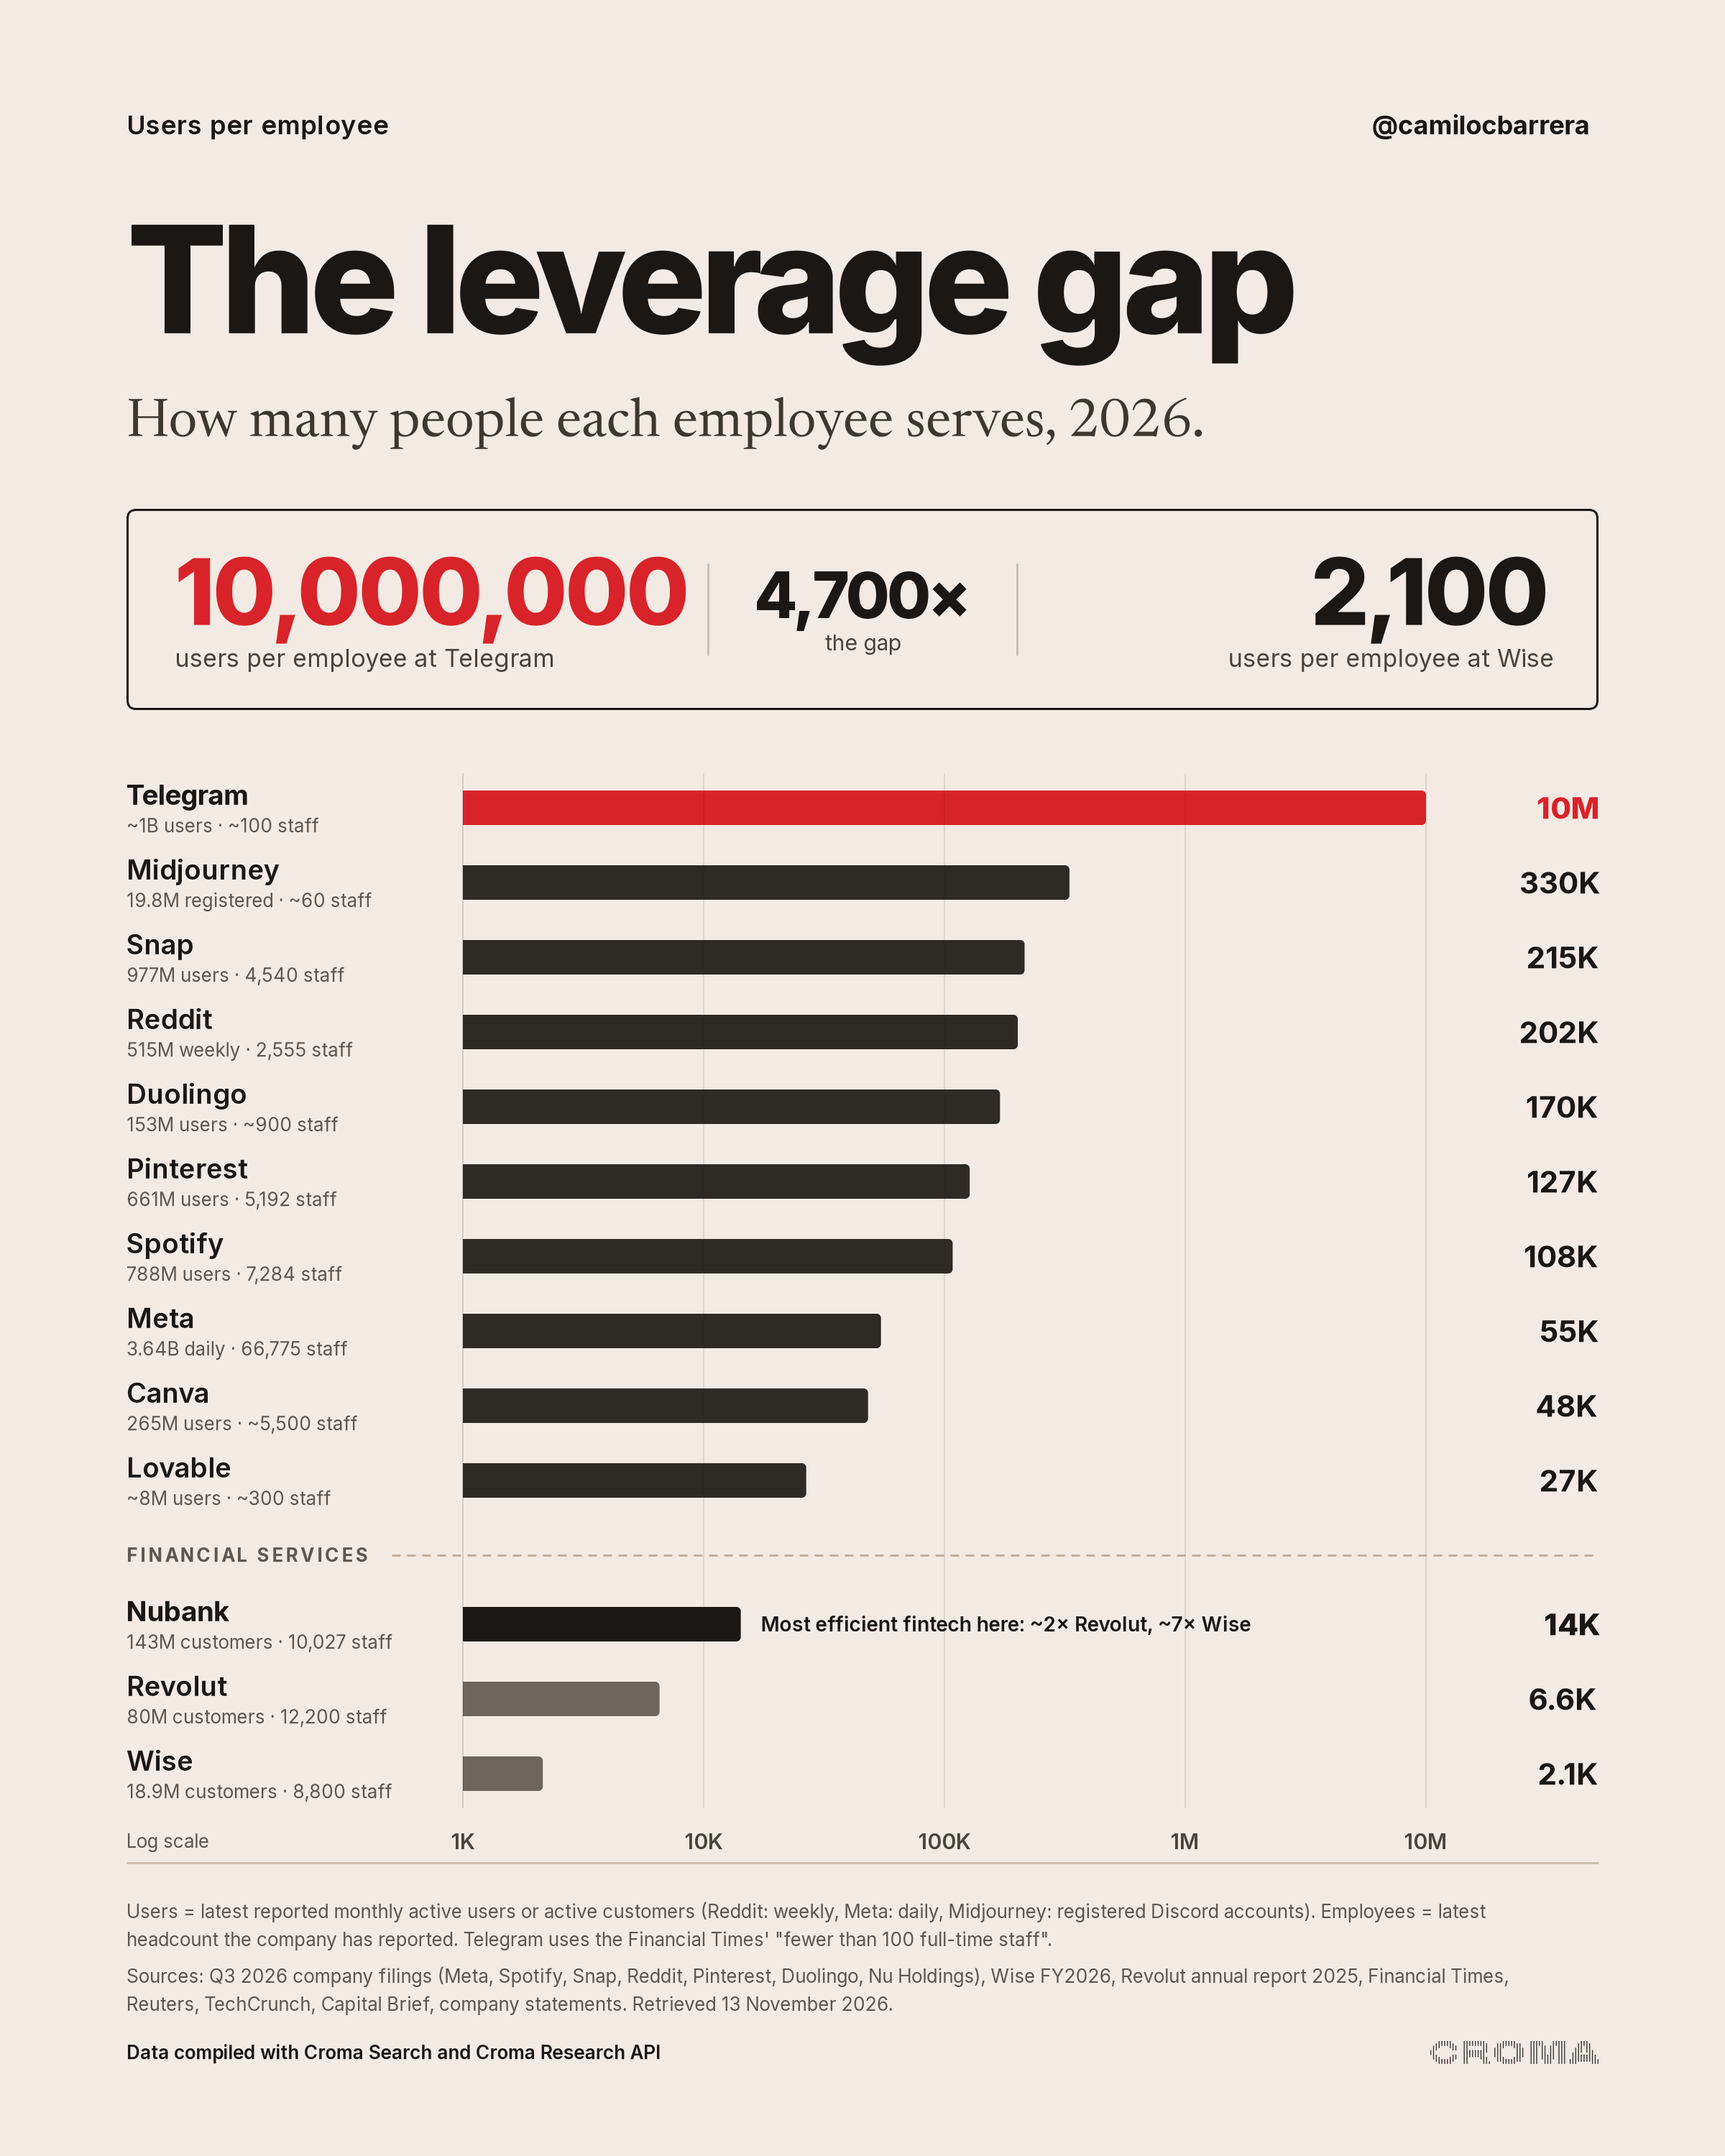

In [16]:
from IPython.display import Image

Image(filename=str(CHARTS / "01-the-leverage-gap.png"), width=600)